# **STEP 2, PART 1.3**

### **Noise-based contours**

Instead of Marasco's levels (0.04 K x 2^n), the contours are now **2 and 3 sigma of LAB's own noise**, measured in the empty channels, in the same way as the data are processed.

The notebook continues from the cleaned, treated LAB profile of `lab_products.npz` that `background_remove.ipynb` (Part 1.2) left off.

In [1]:
import sys, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_fits, load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *
from sigma_comp import *

LAB_PATH = "../Displays/lab.fit.gz"
PRODUCTS = "lab_products.npz"           # written by background_remove.ipynb: the LAB cube to use and its sigma
GRID = Path("./grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("./conv")                   # the convergence-study cubes (tiers 1-4)
PLOT = Path("./plots")
B_CUT = 0
L_CUT = 0
V_DEV = 35.0                            # km/s: |v_dev| below this is disc (Marasco+12 sect. 2.4: 35)
REL_FLOOR = 0.04                        # K: softening of the relative residual (see the module docstring)
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

### LAB Data and Masks

The cube is loaded through the products of `lab_prep.ipynb` (`load_lab_clean`, plus the stored correction if there is one).

`P` carries the numbers, like the sigma, measured on it, so we don't have to copy-paste things.

In [2]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR)
print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: lab_background_correction.npz
Comparison grid: 62 channels x 41 b x 90 l; 163347 LAB voxels with data


In [3]:
RES = {}; MODS = {}

def evaluate_models(names, folder, keep_vec_for=()):
    for nm in names:
        f = Path(folder) / f"{nm}.npz"
        if nm in RES or not f.exists():
            continue
        cube, ax = load_model(nm, folder)
        mod = cmp.model_cmp(cube, ax)
        RES[nm] = cmp.evaluate(mod, keep_vectors=(nm in keep_vec_for)); MODS[nm] = mod

M_INDEX = 2000
LABELS = {0: "neutral", 1: "ionised", 2: "condensation"}
names_M = [f"M{M_INDEX + i:04d}" for i in range(9)]
print(f"{sum((GRID / f'{n}.npz').exists() for n in names_M)} of 9 Table 1 cubes found.")

9 of 9 Table 1 cubes found.


### Which sigma?
* `"empty"`: the number from the empty channels (`background_remove`, steps 2-2b, on the cube loaded above).
* `"null"`: the number from the null test with the real mask (`background_remove`, step 3), which includes the effect of the mask.

If the two differ by more than ~20%, the second is the one that describes the compared voxels. Their ratio is printed below; at the last run it was ~1.02, therefore we continue with `empty`.

The map version (sigma per pixel) is available too; set `SIGMA_MODE = "map"` to contour `data/sigma(l, b)` instead of data against one number. Note that the two telescopes do not have the same noise at 8 degrees (`background_remove` prints the ratio of the map medians), which a single number cannot show. The found south-to-north ratio is ~0.7, therefore we continue with `map`.

In [4]:
SIGMA_SOURCE = "empty"      # "empty" or "null"
SIGMA_MODE = "map"          # "global" (one number, K) or "map" (sigma/pixel, scaled so that its median is the chosen number)
SIGMA_NUM = P.sigma_empty if SIGMA_SOURCE == "empty" else P.sigma_null
SIGMA = SIGMA_NUM if SIGMA_MODE == "global" else P.sigma_map * SIGMA_NUM / np.nanmedian(P.sigma_map[cmp.b != 0])

print(f"Sigma: empty channels {P.sigma_empty*1e3:.2f} mK, null test {P.sigma_null*1e3:.2f} mK "
      f"(ratio {P.sigma_null/P.sigma_empty:.2f})")
print(f"Sigma = {SIGMA_NUM*1e3:.2f} mK  ->  2 sigma = {2*SIGMA_NUM*1e3:.1f} mK, 3 sigma = {3*SIGMA_NUM*1e3:.1f} mK")
print(f"Marasco's lowest contour, 0.04 K, is {0.04/SIGMA_NUM:.1f} sigma of the smoothed data.")
print(f"The relative-residual floor eps = {REL_FLOOR} K is the same {REL_FLOOR/SIGMA_NUM:.1f} sigma.")

Sigma: empty channels 3.12 mK, null test 3.24 mK (ratio 1.04)
Sigma = 3.12 mK  ->  2 sigma = 6.2 mK, 3 sigma = 9.4 mK
Marasco's lowest contour, 0.04 K, is 12.8 sigma of the smoothed data.
The relative-residual floor eps = 0.04 K is the same 12.8 sigma.


## 1. The models against LAB with sigma contours
Two styles of the same plot, same data. 

* **style = 'lab'** (the cells just below): LAB filled in graded blues (lightest above 3 sigma, darkest above 300 sigma), the model scaled to LAB's flux in the halo region as coloured contour lines (dashed 3 sigma; solid is the rest, thicker with the level). 

* **style = 'model'** (the second cell of each pair): the model filled in graded tints of its colour (lightest above 3 sigma, full colour above 300 sigma) and LAB as black **dashed** contour lines, thicker with the level; easier to read where the two overlap. 

* Gray is masked always, 

* Blank inside the kept region means below 3 sigma, and nothing else.

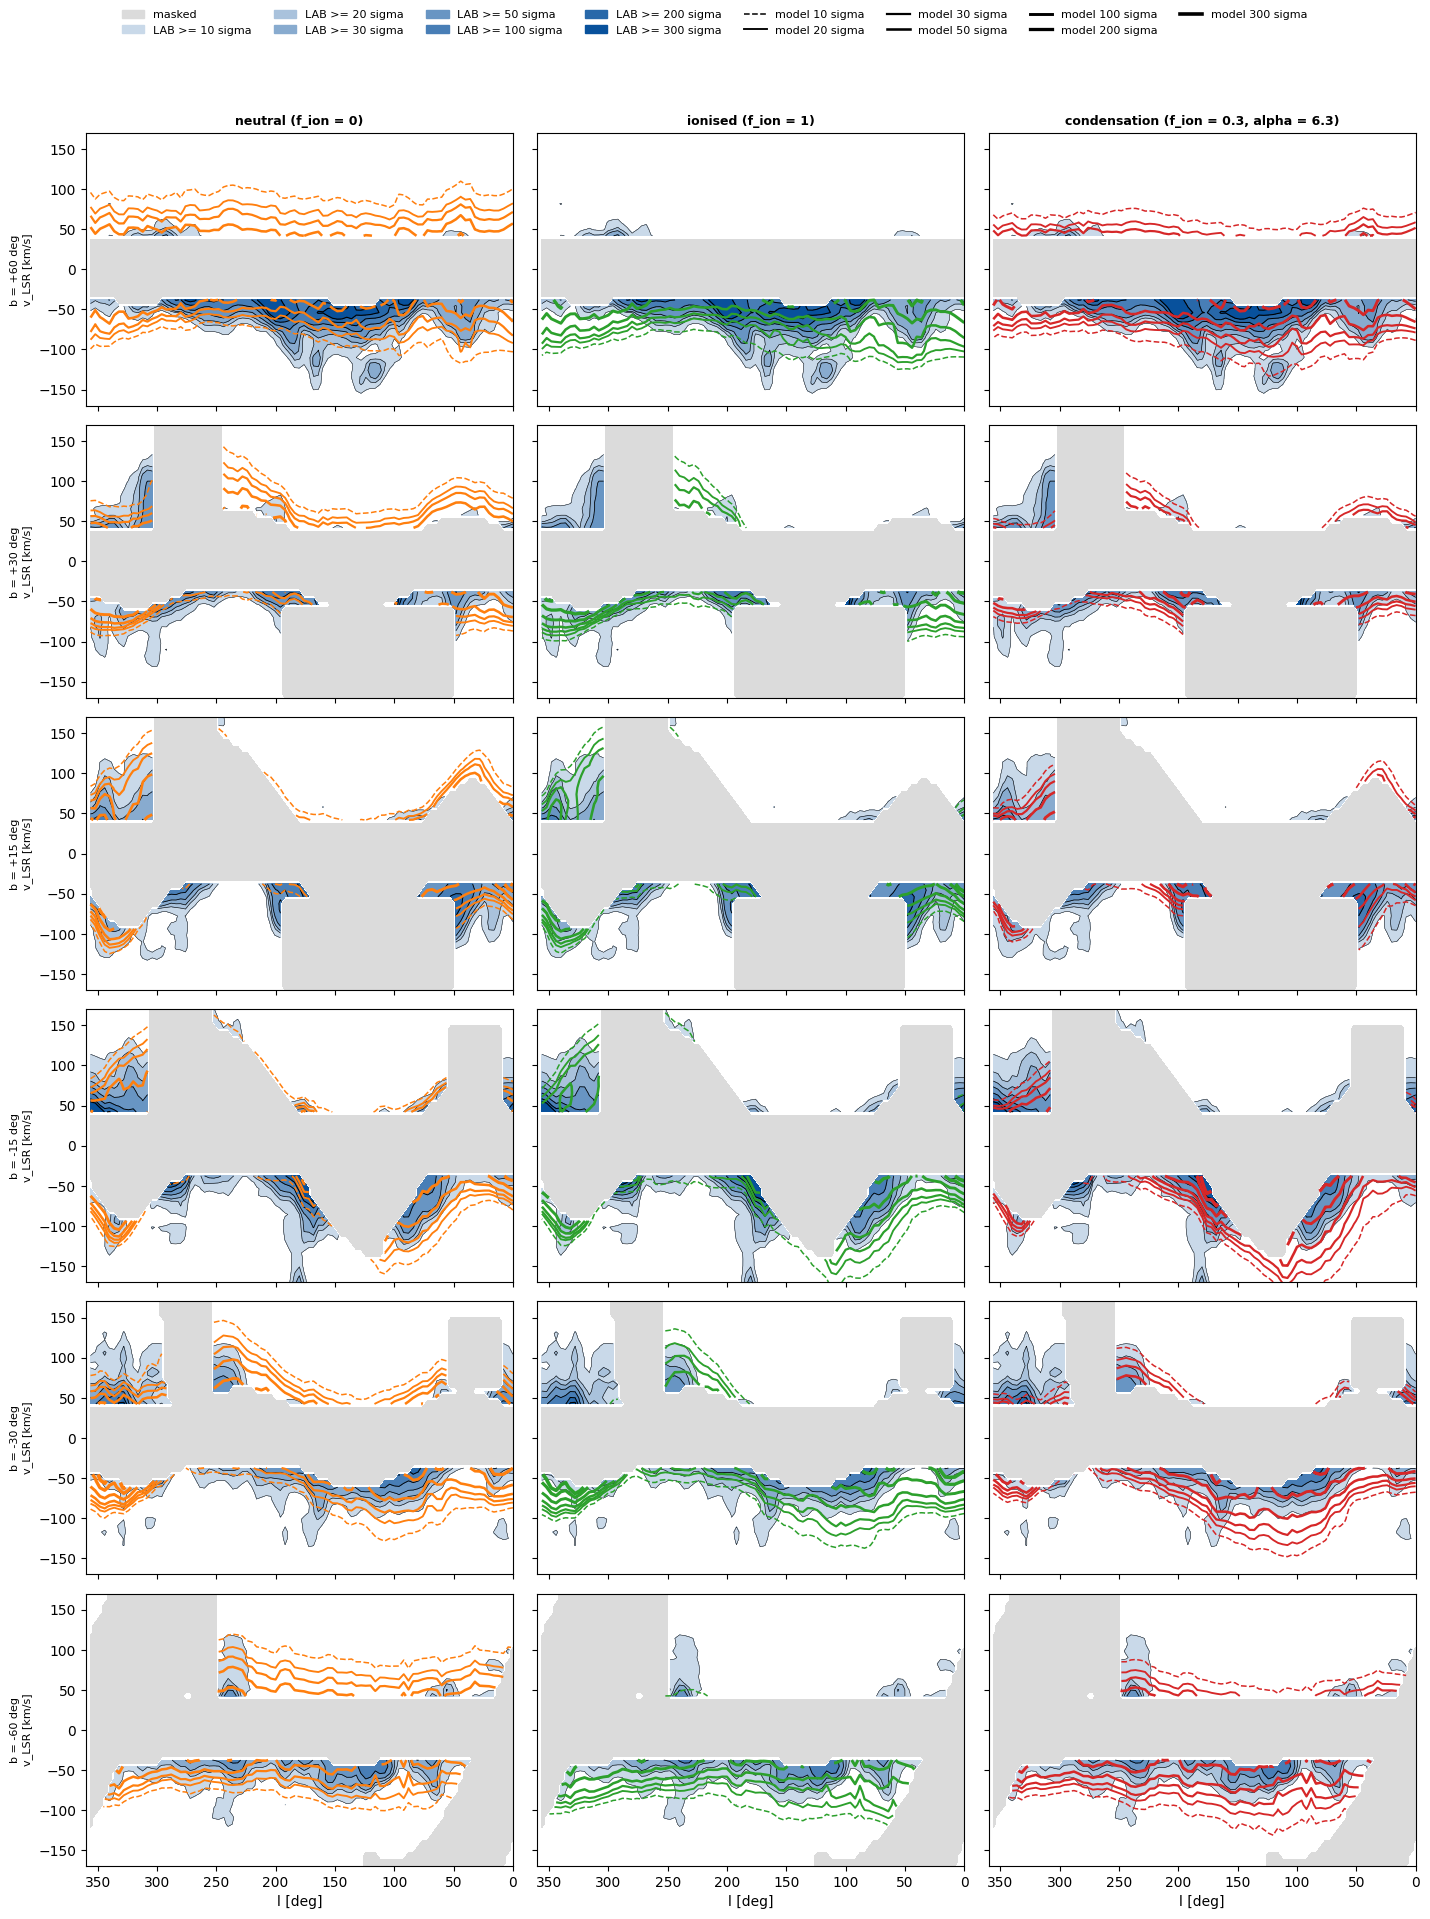

In [5]:
evaluate_models(names_M, GRID, keep_vec_for=tuple(names_M))

sc = lambda n: cmp.scaled(MODS[n], RES[n]["scale"])
models = [(sc(names_M[0]), "neutral (f_ion = 0)"), 
          (sc(names_M[3]), "ionised (f_ion = 1)"), 
          (sc(names_M[6]), "condensation (f_ion = 0.3, alpha = 6.3)")]

plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60))
plt.savefig(PLOT / "lv_sigma_lab.png", dpi=150)
plt.show()

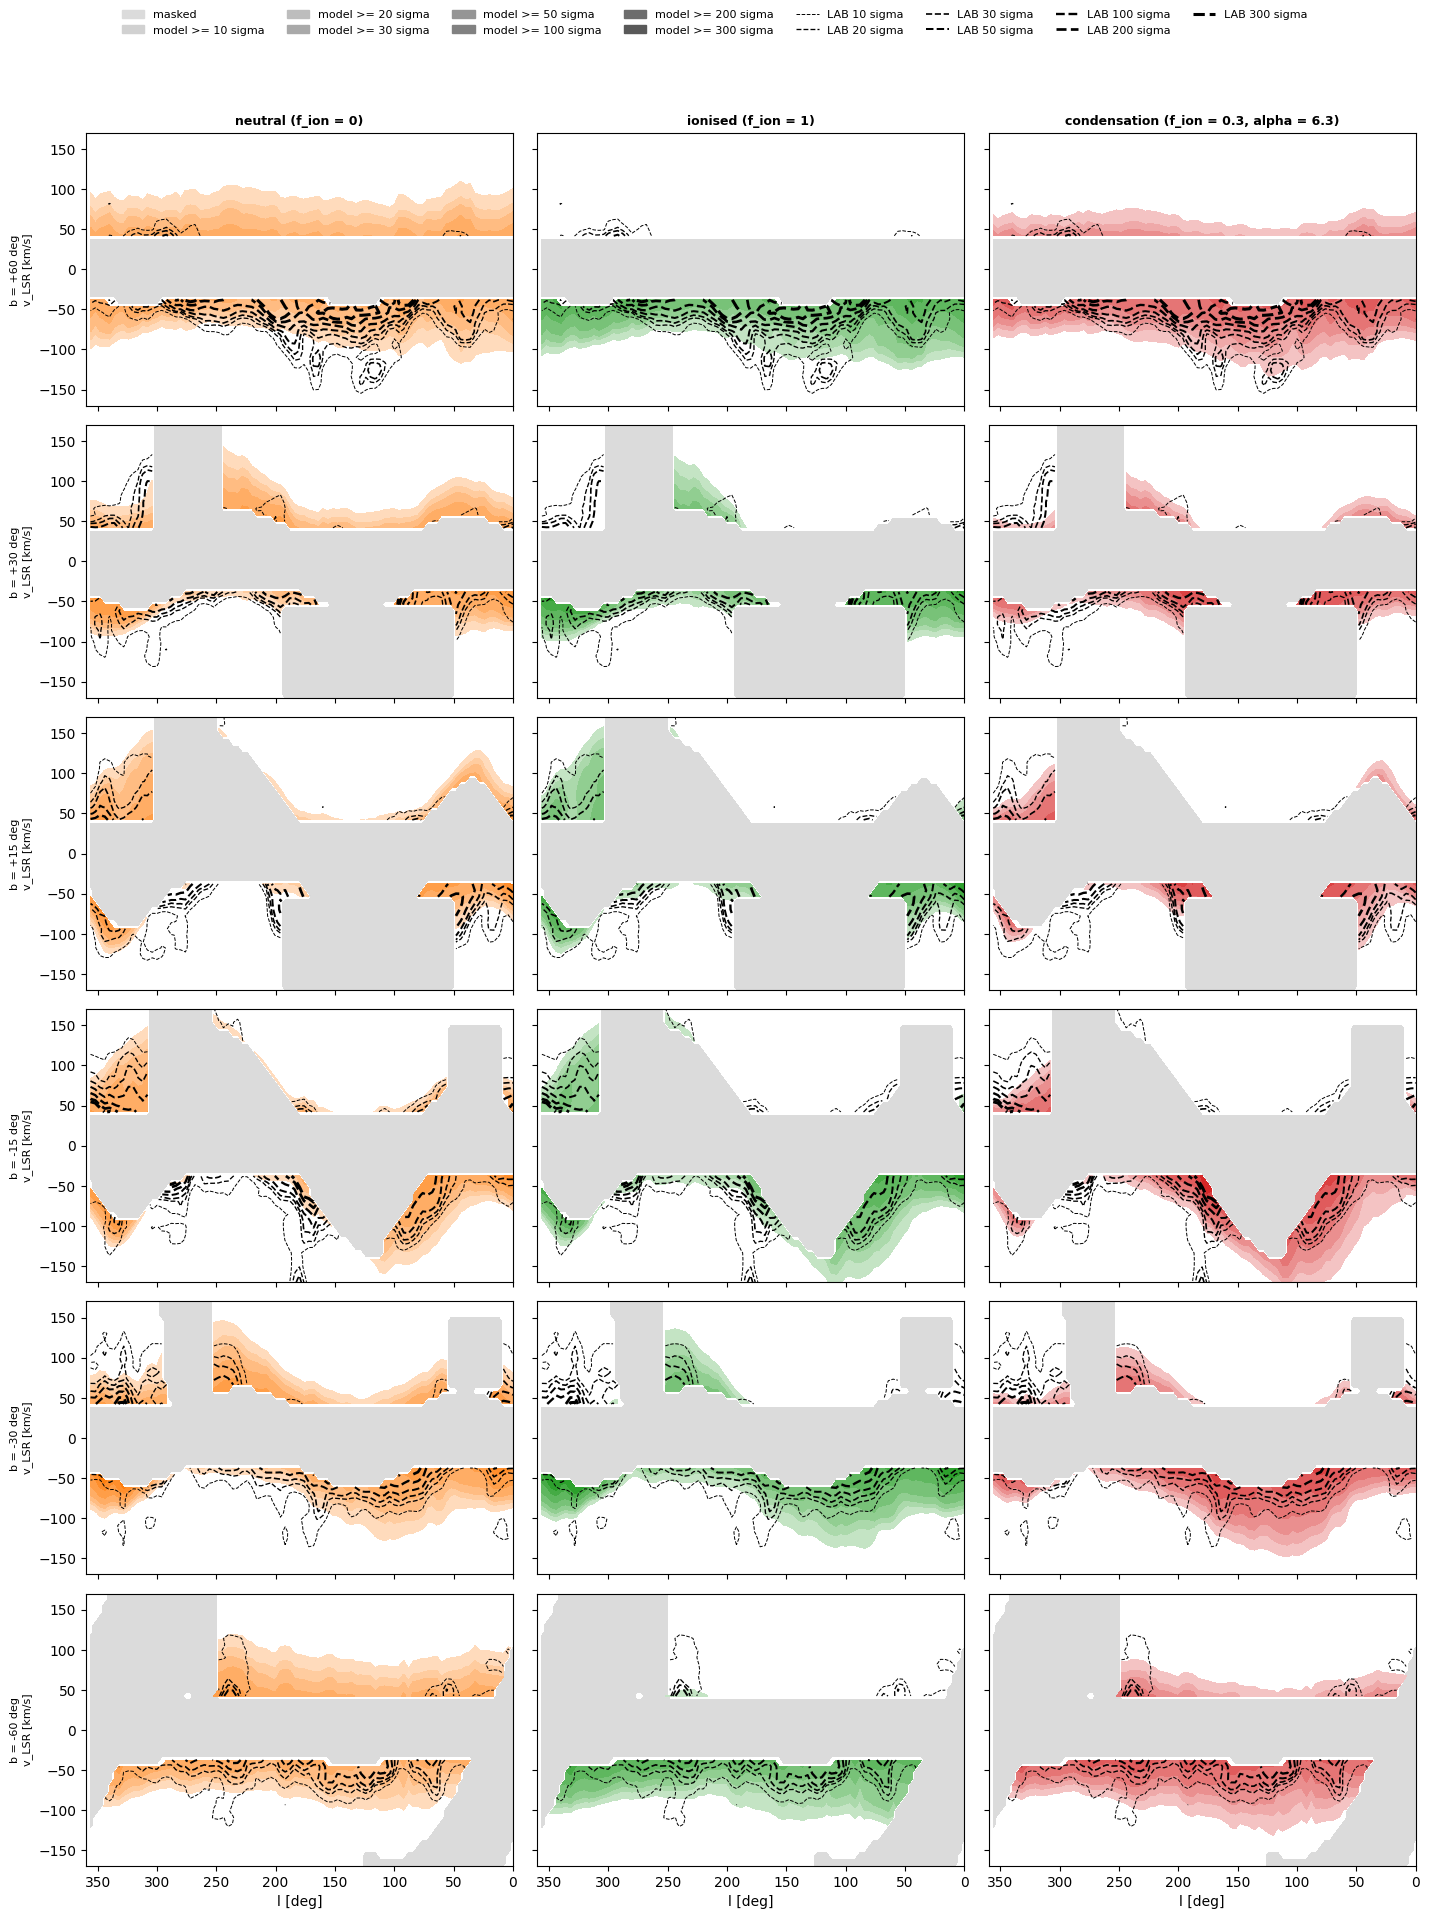

In [6]:
plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60), style="model")
plt.savefig(PLOT / "lv_sigma_model.png", dpi=150)
plt.show()

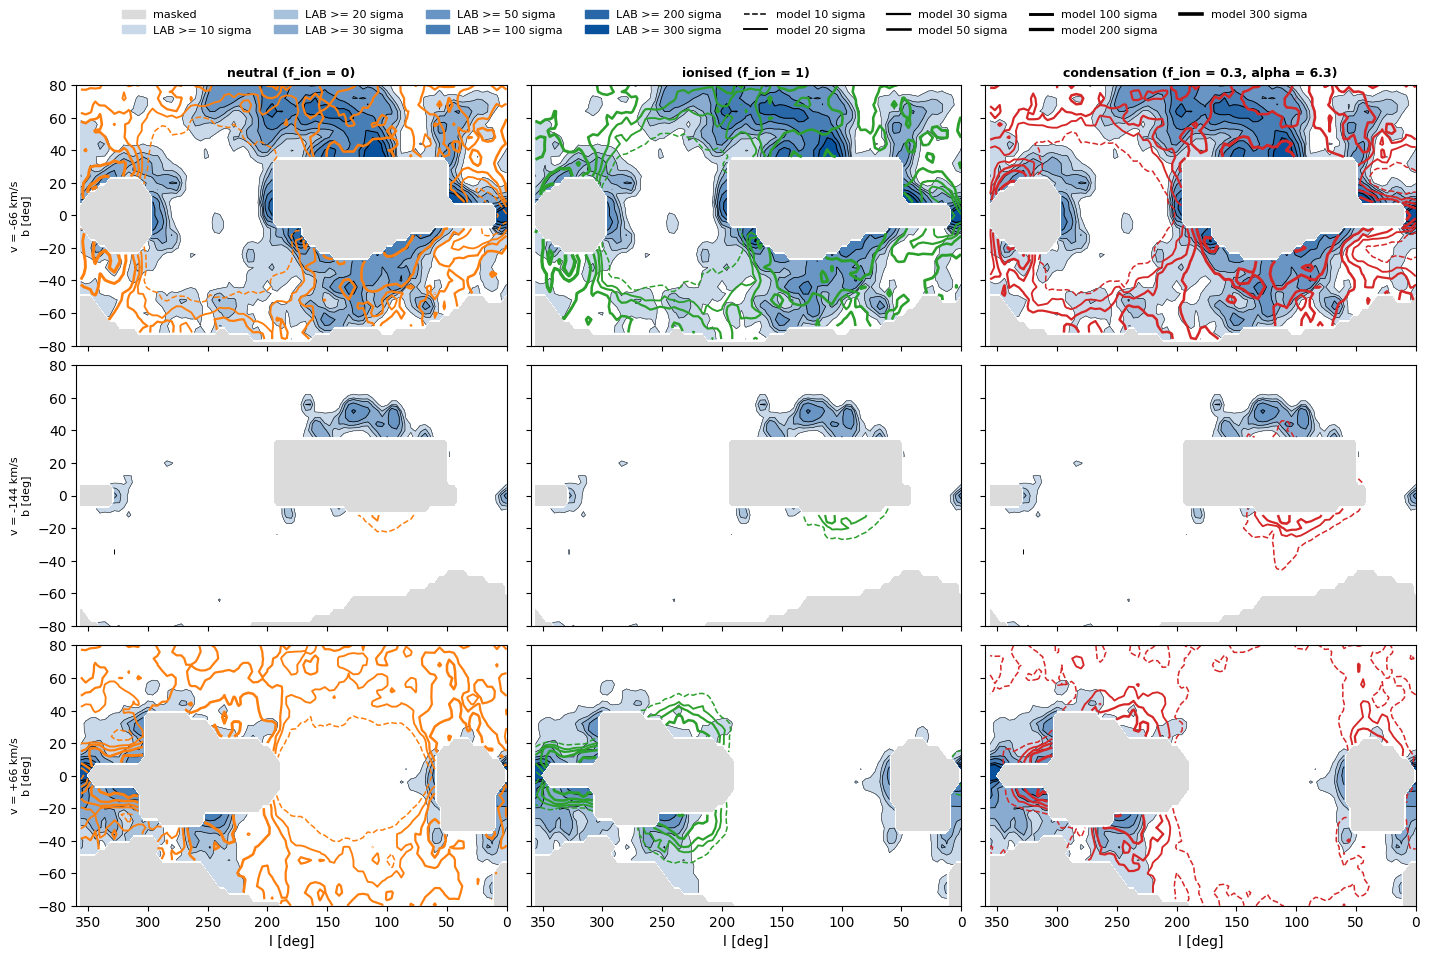

In [7]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0))
plt.savefig(PLOT / "channel_sigma_lab.png", dpi=150)
plt.show()

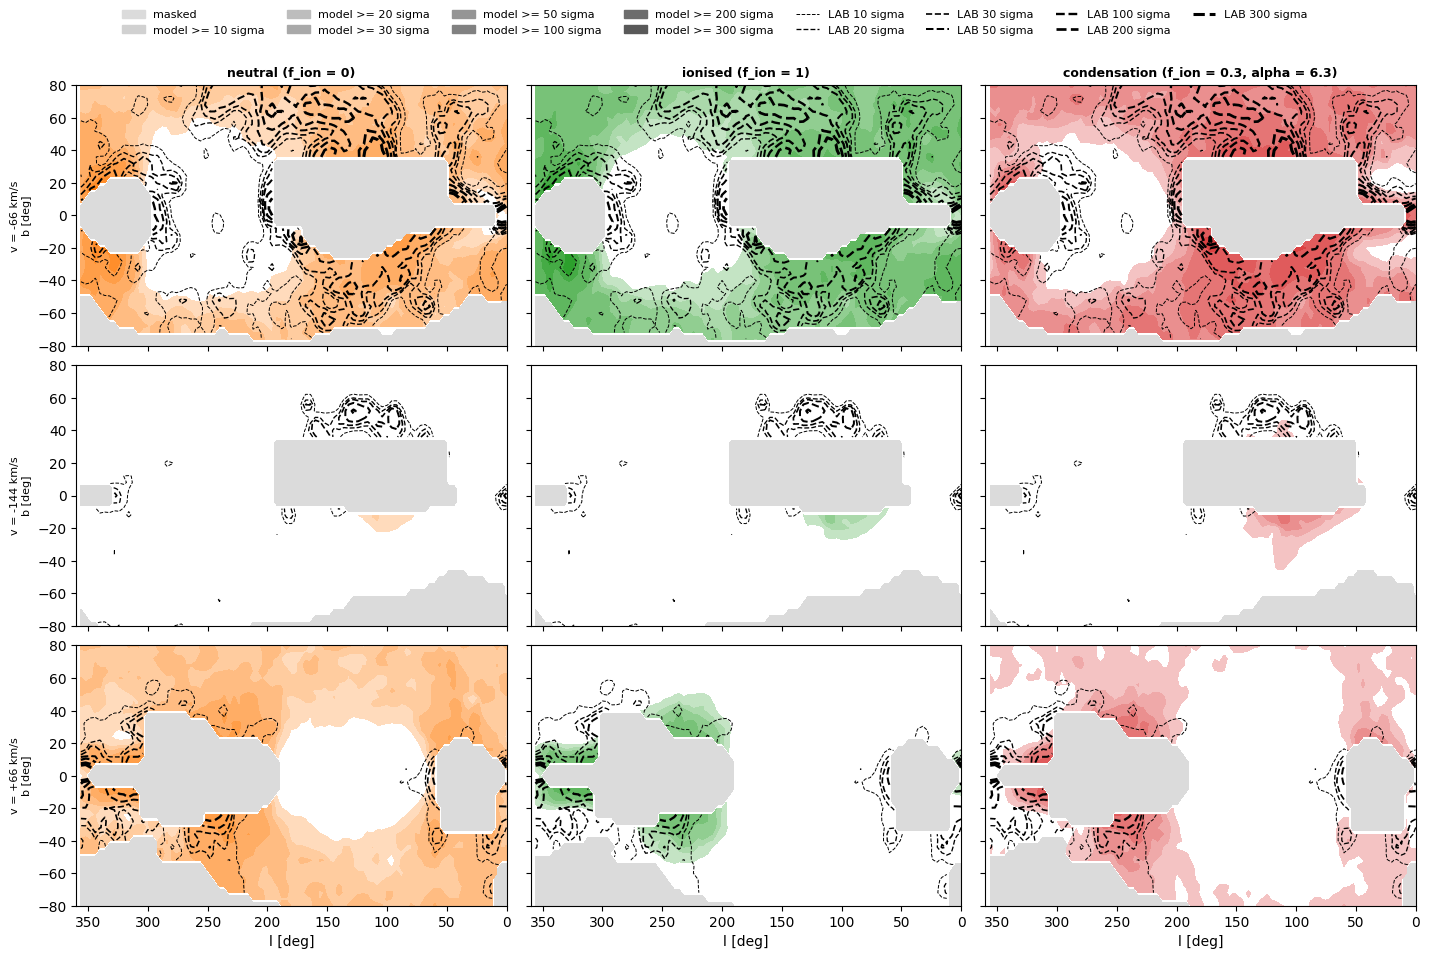

In [8]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0), style="model")
plt.savefig(PLOT / "channel_sigma_model.png", dpi=150)
plt.show()

### 1b. Footprints: How broad is the model?
Areas (sum of $\cos(b)$ over voxels) above $k$ sigma. 
* **area ratio** = model / LAB (> 1: the model is broader),
* **recall** = share of the LAB footprint the model also covers,
* **precision** = share of the model footprint that LAB also has,
* **faint flux** = share of the total flux in voxels *below* $k$ sigma, i.e. what a threshold throws away. 

The two plots show the area ratio by |b| and by velocity, where the model is broader.

*IoU means intersection over union: `iou = area_both / (area_data + area_model - area_both)`*

  k model          area ratio  recall precision    IoU   n LAB  n model  faint flux LAB  faint flux model
  2 neutral              0.70    0.56      0.79   0.49   69592    54701            1.9%              2.0%
  2 ionised              0.48    0.43      0.89   0.41   69592    34107            1.9%              1.2%
  2 condensation         0.54    0.47      0.86   0.44   69592    41817            1.9%              1.4%
  3 neutral              0.80    0.58      0.73   0.48   54456    49098            4.7%              3.1%
  3 ionised              0.54    0.47      0.86   0.44   54456    31041            4.7%              1.8%
  3 condensation         0.62    0.51      0.81   0.45   54456    38266            4.7%              2.1%
  5 neutral              0.99    0.62      0.63   0.46   37208    42224            9.7%              5.0%
  5 ionised              0.68    0.54      0.79   0.47   37208    27049            9.7%              3.1%
  5 condensation         0.79    0.57      0.7

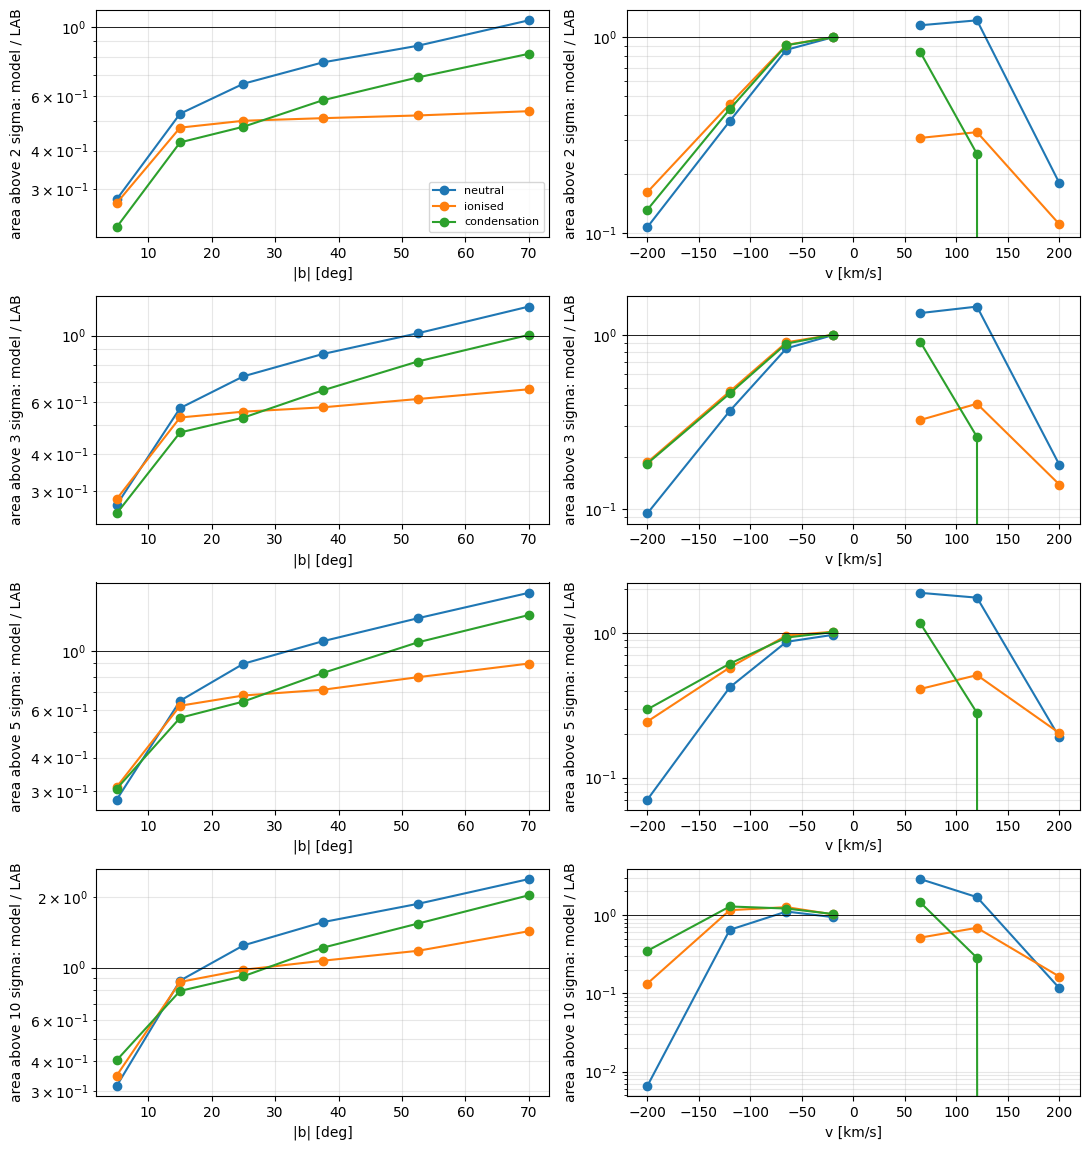

In [9]:
sigma_for_stats = SIGMA
KS_FP = (2.0, 3.0, 5.0, 10.0)
FP = {LABELS[g]: footprint_stats(RES[names_M[3 * g]]["vec"], cmp, sigma_for_stats, ks=KS_FP) for g in range(3)}

print(f"{'k':>3s} {'model':14s} {'area ratio':>10s} {'recall':>7s} {'precision':>9s} "
      f"{'IoU':>6s} {'n LAB':>7s} {'n model':>8s} {'faint flux LAB':>15s} {'faint flux model':>17s}")

for k in KS_FP:
    for fam, st in FP.items():
        s = st[k]
        print(f"{k:3g} {fam:14s} {s['area_ratio']:10.2f} {s['recall']:7.2f} {s['precision']:9.2f} "
              f"{s['iou']:6.2f} {s['n_D']:7d} {s['n_M']:8d} {100*s['faint_flux_D']:14.1f}% {100*s['faint_flux_M']:16.1f}%")

plot_footprint(FP, ks=KS_FP)
plt.show()

## 1c. The model's own MC noise against LAB's sigma
The model is a finite sample of particles. Per brightness band of the seed-mean (in units of LAB's sigma), the seed-to-seed rms of the model: if it is comparable to sigma in the 2-3 sigma band, the model's own 2-3 sigma contours are ragged and their position is not a property of the model. Ionized seems to be the noisiest.

In [10]:
for g in range(3):
    rows = model_seed_noise([sc(n) for n in names_M[3 * g:3 * g + 3]], SIGMA)
    print(LABELS[g])
    for r in rows:
        print(f"   seed-mean in [{r['band'][0]:g}, {r['band'][1]:g}) sigma: {r['n']:6d} voxels, "
              f"seed-to-seed rms = {r['sd_over_sigma']:.2f} sigma = {100*r['sd_over_mean']:.0f}% of the mean")

neutral
   seed-mean in [1, 2) sigma:   9500 voxels, seed-to-seed rms = 0.28 sigma = 20% of the mean
   seed-mean in [2, 3) sigma:   5528 voxels, seed-to-seed rms = 0.38 sigma = 15% of the mean
   seed-mean in [3, 6) sigma:   9670 voxels, seed-to-seed rms = 0.48 sigma = 11% of the mean
ionised
   seed-mean in [1, 2) sigma:   6072 voxels, seed-to-seed rms = 0.51 sigma = 37% of the mean
   seed-mean in [2, 3) sigma:   3366 voxels, seed-to-seed rms = 0.57 sigma = 23% of the mean
   seed-mean in [3, 6) sigma:   5660 voxels, seed-to-seed rms = 0.81 sigma = 19% of the mean
condensation
   seed-mean in [1, 2) sigma:   7239 voxels, seed-to-seed rms = 0.32 sigma = 23% of the mean
   seed-mean in [2, 3) sigma:   3830 voxels, seed-to-seed rms = 0.43 sigma = 18% of the mean
   seed-mean in [3, 6) sigma:   6494 voxels, seed-to-seed rms = 0.61 sigma = 15% of the mean


## 2. Residuals with thresholds
The flux scale is the paper's (all kept voxels, global) in every row. Rows:

* **base**: all voxels, as before;
* **thr k**: both cubes thresholded at $k$ sigma (values below set to 0), summed over all voxels;
* **det k**: only voxels where LAB or the model exceeds $k$ sigma, values unaltered;
* **detrn k**: the same voxels, the model re-normalised to LAB's flux on them.

`rels` is the relative residual with $\epsilon = \sigma$ instead of the fixed floor. Thresholding the data alone can bias the flux upwards where noise dominates. `det` keeps the values and only drops voxels where neither cube is significant, which is the cleaner version.

variant    voxels               abs                |                sq                |               rel                |               rels              
                   neut/cond   ion/cond   neut/ion |  neut/cond   ion/cond   neut/ion |  neut/cond   ion/cond   neut/ion |  neut/cond   ion/cond   neut/ion
base       160304      1.167      1.138   1.026*   |      1.324      1.338   0.990    |      1.103      1.024   1.077*   |      1.001      1.018   0.983   
thr2       160304      1.182      1.141   1.036*   |      1.325      1.338   0.991    |      1.148      1.018   1.128*   |      1.065      1.014   1.051*  
det2        77497      1.181      1.144   1.032*   |      1.325      1.338   0.990    |      1.147      1.025   1.120*   |      1.062      1.022   1.039*  
detrn2      77497      1.187      1.144   1.037*   |      1.327      1.334   0.995    |      1.149      1.025   1.121*   |      1.063      1.023   1.039*  
thr3       160304      1.189      1.139   1.044*   |      1.326 

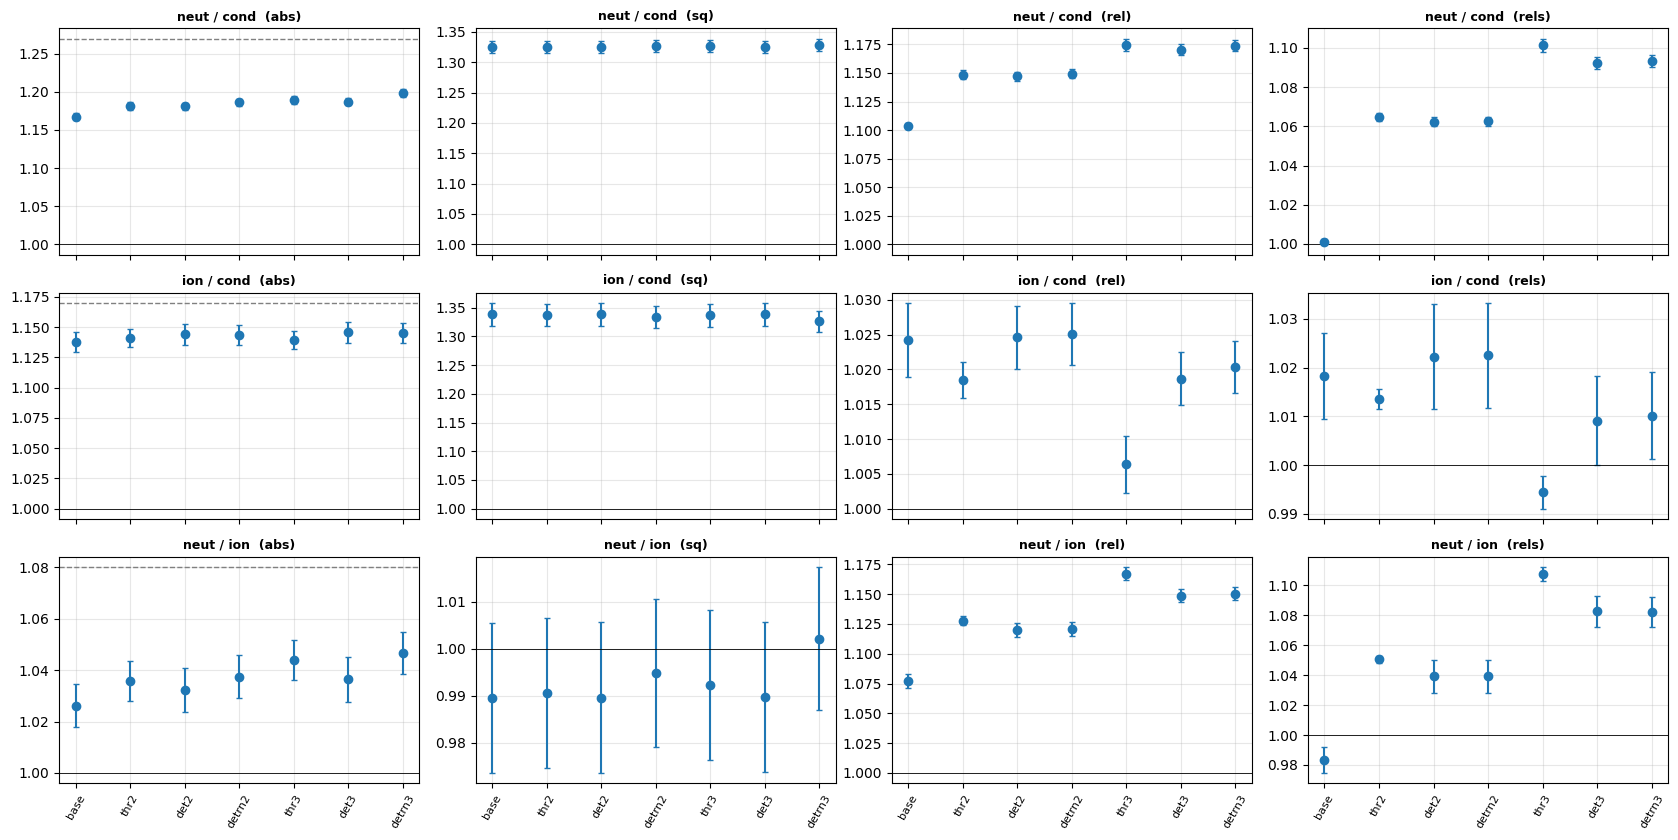

In [11]:
VAR = {nm: residual_variants(RES[nm]["vec"], SIGMA, ks=(2.0, 3.0), rel_floor=REL_FLOOR) for nm in names_M}
variants = list(VAR[names_M[0]])

def fam_stats(variant, obs):
    m, se = [], []
    for g in range(3):
        x = np.array([VAR[n][variant][obs] for n in names_M[3 * g:3 * g + 3]])
        m.append(x.mean())
        se.append(x.std(ddof=1) / np.sqrt(len(x)))

    return np.array(m), np.array(se)

def ratio3(variant, obs):
    m, se = fam_stats(variant, obs)
    f = lambda a, b: (m[a] / m[b], m[a] / m[b] * np.hypot(se[a] / m[a], se[b] / m[b]))
    return f(0, 2), f(1, 2), f(0, 1)          # neut/cond, ion/cond, neut/ion

print(f"{'variant':9s} {'voxels':>7s} " + " | ".join(f"{o:^32s}" for o in VARIANT_OBS))
print(f"{'':9s} {'':>7s} " + " | ".join(f"{'neut/cond':>10s} {'ion/cond':>10s} {'neut/ion':>10s}" for o in VARIANT_OBS))

for v_ in variants:
    cells = []
    for o in VARIANT_OBS:
        (a, _), (b_, _), (ni, eni) = ratio3(v_, o)
        cells.append(f"{a:10.3f} {b_:10.3f} {ni:7.3f}{'*' if abs(ni - 1) > 2 * eni else ' '}  ")

    print(f"{v_:9s} {int(np.mean([VAR[n][v_]['n'] for n in names_M])):7d} " + " | ".join(cells))

print("* neut/ion differs from 1 by more than 2 standard errors (3 seeds per family).  "
      "Paper (absolute): neut/cond 1.27, ion/cond 1.17, neut/ion 1.08")

fig, axs = plt.subplots(3, len(VARIANT_OBS), figsize=(4.2 * len(VARIANT_OBS), 8.5), sharex=True)
for j, o in enumerate(VARIANT_OBS):
    for i, (ttl, idx) in enumerate((("neut / cond", 0), ("ion / cond", 1), ("neut / ion", 2))):
        r = [ratio3(v_, o)[idx] for v_ in variants]
        axs[i, j].errorbar(range(len(variants)), [x[0] for x in r], yerr=[x[1] for x in r], fmt="o", capsize=2)
        axs[i, j].axhline(1.0, color="k", lw=0.6); axs[i, j].grid(alpha=0.3)

        if o == "abs":
            axs[i, j].axhline([1.27, 1.17, 1.08][i], color="gray", ls="--", lw=1)
            
        axs[i, j].set_title(f"{ttl}  ({o})", fontsize=9, weight="bold")

for a in axs[-1]:
    a.set_xticks(range(len(variants)))
    a.set_xticklabels(variants, rotation=60, fontsize=8)
plt.tight_layout()
plt.show()

## 3. The |l| and |b| scans again, with thresholds

In [12]:
wrap = lambda l: (np.asarray(l, float) + 180.0) % 360.0 - 180.0

def make_cmp_variant(bcut=None, drop=None, cfg_=None):
    kl = build_keep(lab, ax_lab, bcut)
    if drop is not None: kl = kl & ~drop(*ax_lab)
    def bk(cube, axes):
        k = build_keep(cube, axes, bcut)
        return k & ~drop(*axes) if drop is not None else k
    return MarascoComparison(lab, ax_lab, kl, bk, to_full, cfg_ or cfg, rel_floor=REL_FLOOR)

SCANS = globals().get("SCANS", {})

def run_scan(kind, cuts, sigma, ks=(2.0, 3.0)):
    assert kind in ("l", "b")
    f = GRID / f"sigma_scan_{kind}.pkl"
    meta = dict(kind=kind, B_CUT=B_CUT, L_CUT=L_CUT, V_DEV=V_DEV, REL_FLOOR=REL_FLOOR, 
                sigma=None if np.ndim(sigma) else round(float(sigma), 7), ks=tuple(ks), names=tuple(names_M))
    store = SCANS.get(kind)

    if store is None:
        store = {}
        if f.exists():
            saved = pickle.load(open(f, "rb"))
            if saved.get("meta") == meta: store = saved["scan"]
            else: print(f"[{kind}] cached scan was made with other settings and is ignored (overwritten when saved)")

        SCANS[kind] = store

    for cut in cuts:
        if cut in store: 
            continue
        
        t0 = time.time()
        if cut > 0:
            drop = (lambda l, b, v, c=cut: (np.abs(wrap(l)) < c)[None, None, :]) if kind == "l" else (lambda l, b, v, c=cut: (np.abs(b) < c)[None, :, None])
        
        else:
            drop = None
        
        cv = make_cmp_variant(drop=drop); out = {}
        for nm in names_M:
            cube, ax_ = load_model(nm, GRID)
            r = cv.evaluate(cv.model_cmp(cube, ax_), keep_vectors=True)
            out[nm] = residual_variants(r["vec"], sigma, ks, REL_FLOOR)

        store[cut] = out
        pickle.dump(dict(meta=meta, scan=store), open(f, "wb"))
        print(f"[{kind}] cut {cut}: done in {time.time() - t0:.0f} s")

    return store

def plot_scan(kind, variants_shown=("base", "thr3", "det2", "det3"), obs_shown=("abs", "sq", "rel", "rels")):
    store = SCANS[kind]; cuts = sorted(store)
    def r3(cut, var, obs):
        m, se = [], []
        for g in range(3):
            x = np.array([store[cut][n][var][obs] for n in names_M[3 * g:3 * g + 3]])
            m.append(x.mean())
            se.append(x.std(ddof=1) / np.sqrt(len(x)))

        m, se = np.array(m), np.array(se)

        f = lambda a, b: (m[a] / m[b], m[a] / m[b] * np.hypot(se[a] / m[a], se[b] / m[b]))
        return f(0, 2), f(1, 2), f(0, 1)
    
    fig, axs = plt.subplots(3, len(obs_shown), figsize=(4.4 * len(obs_shown), 9), sharex=True)

    for j, o in enumerate(obs_shown):
        for i, ttl in enumerate(("neut / cond", "ion / cond", "neut / ion")):
            for var in variants_shown:

                y = [r3(c, var, o)[i] for c in cuts]
                axs[i, j].errorbar(cuts, [x[0] for x in y], yerr=[x[1] for x in y], fmt="o-", ms=3, capsize=2, label=var)

            axs[i, j].axhline(1.0, color="k", lw=0.6)
            axs[i, j].grid(alpha=0.3)
            axs[i, j].set_title(f"{ttl}  ({o})", fontsize=9, weight="bold")

            if o == "abs":
                axs[i, j].axhline([1.27, 1.17, 1.08][i], color="gray", ls="--", lw=1)

        axs[-1, j].set_xlabel(f"remove |{kind}| < cut [deg]")

    axs[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

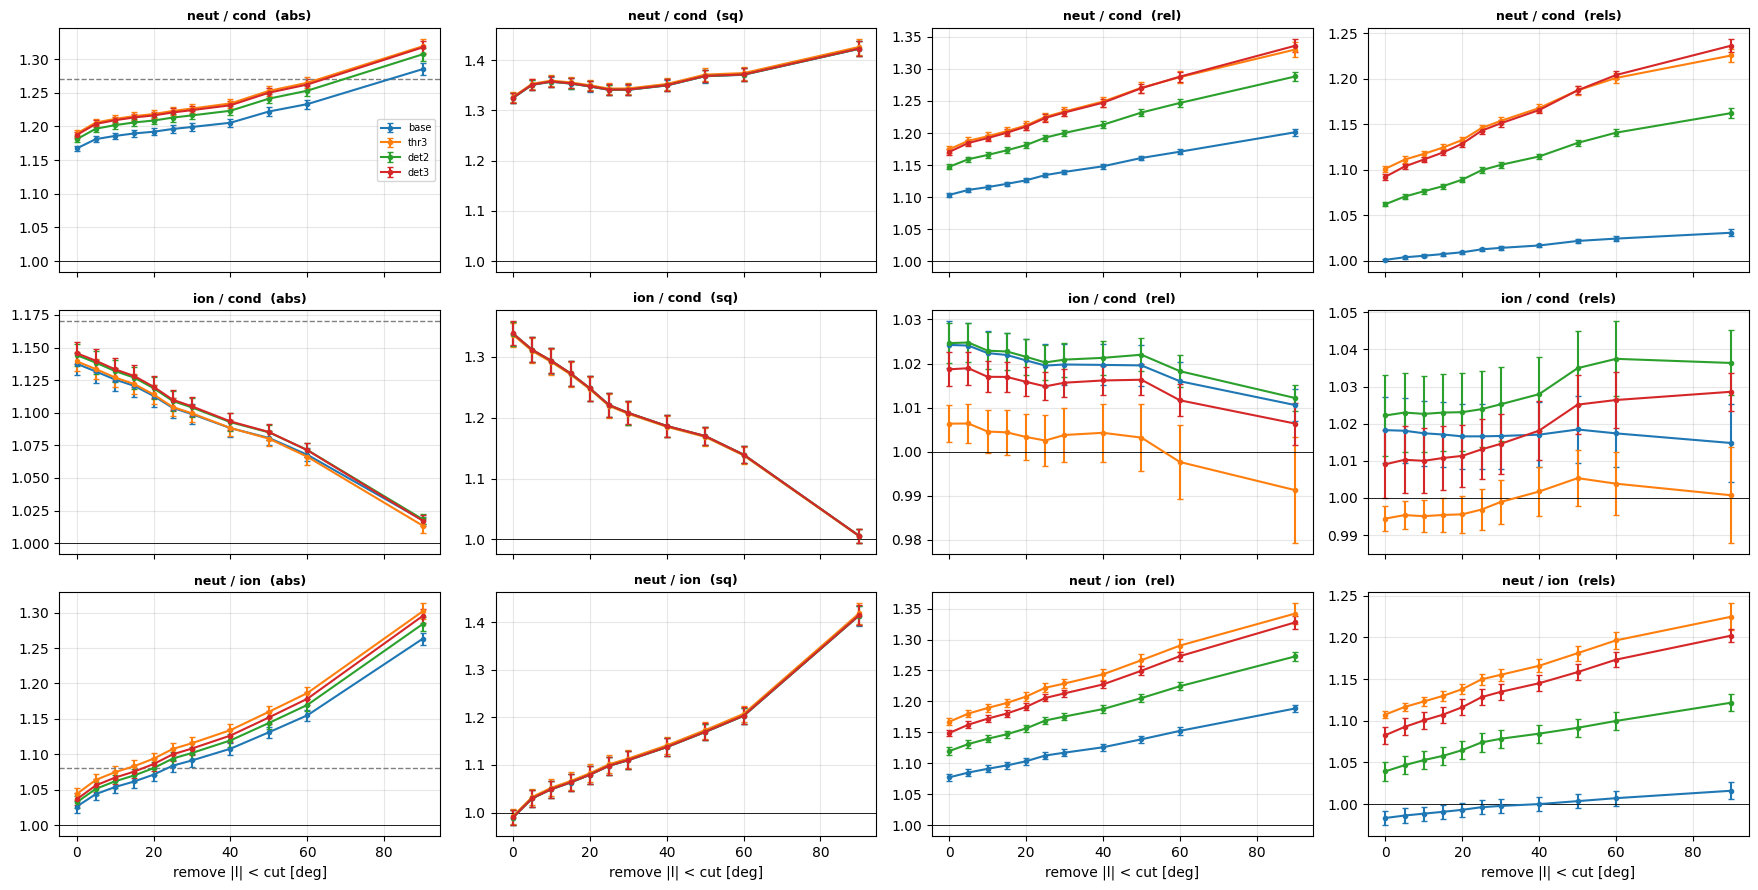

In [13]:
L_CUTS = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 90]
B_CUTS = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70]
run_scan("l", L_CUTS, SIGMA)
plot_scan("l")

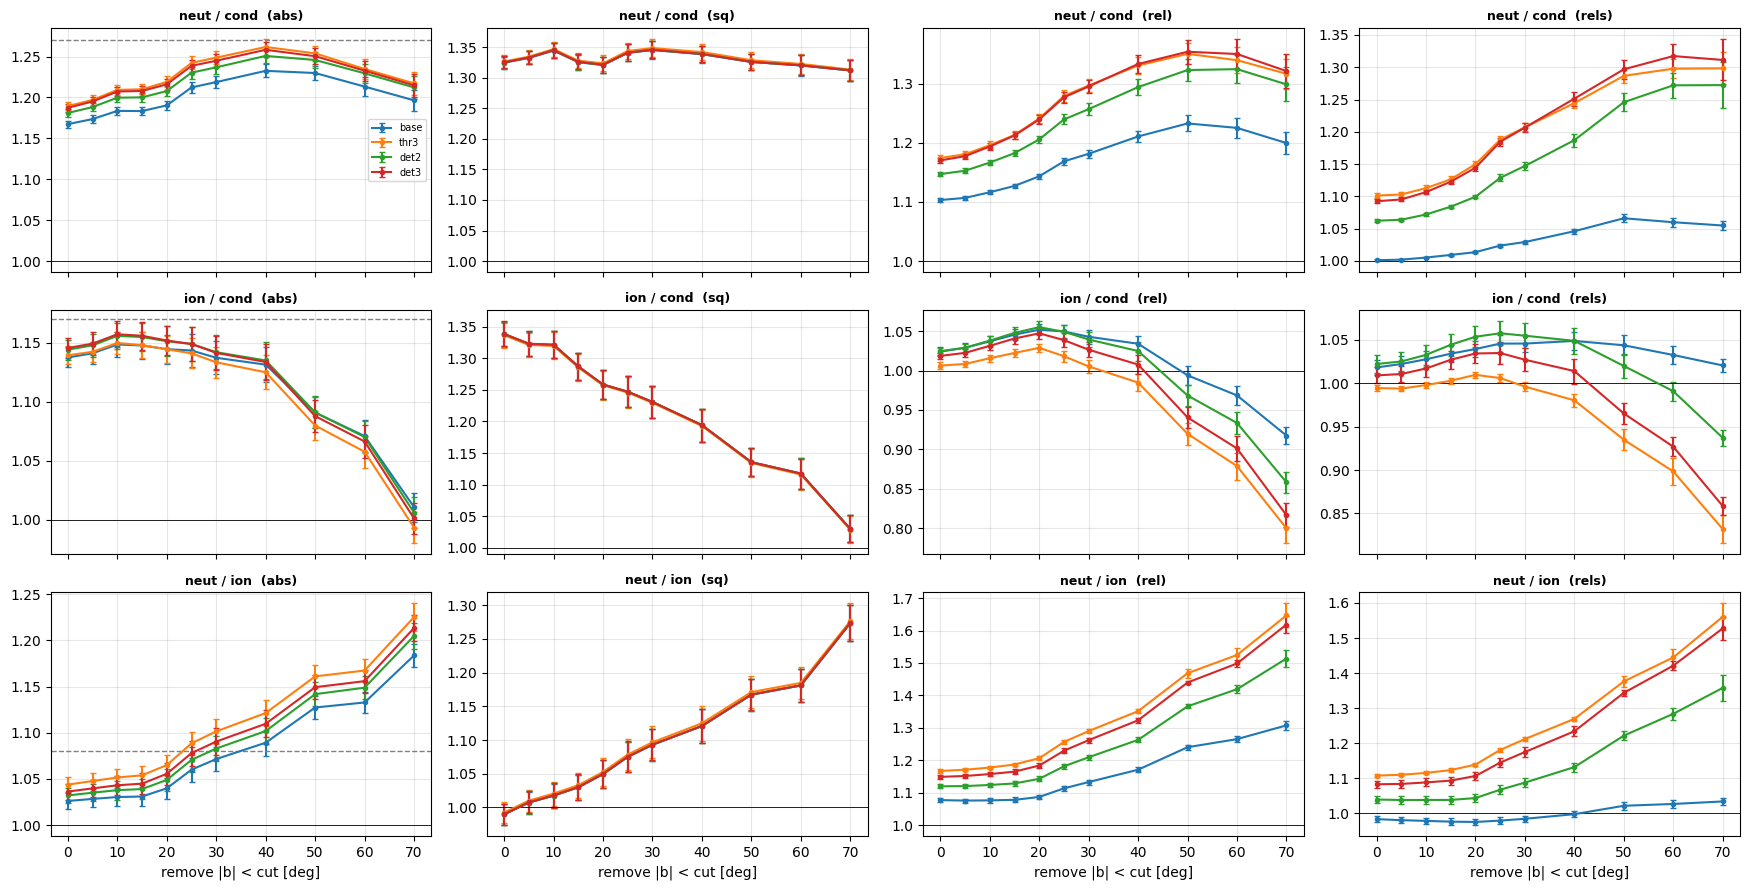

In [14]:
run_scan("b", B_CUTS, SIGMA)
plot_scan("b")

## 4. Follow-up checks
**a) Marasco's own levels:** The same footprint numbers at 0.04 / 0.08 / 0.16 K (tuples are `(area ratio model/LAB, recall)`). Above 1 means the model is broader than LAB at that brightness.

**b) Baseline:** Sky mean of every empty 8 km/s channel after the pipeline. Anything beyond about ±2 mK (0.5 sigma) would be a baseline problem.

**c) Floor:** For any model that is the same at +b and -b, the residual cannot be smaller than the sum over (+b, -b) pairs of |D_N - D_S| (LAB only, any flux scale). `floor / R` is the share of each model's residual that no such model could remove; `R / LAB flux` is the share of LAB's flux that is misplaced. The last two lines give the model ratios before and after taking the floor out.

In [15]:
for g in range(3):
    st = footprint_stats(RES[names_M[3 * g]]["vec"], cmp, 0.04, ks=(1.0, 2.0, 4.0))
    print(f"{LABELS[g]:14s}", 
          {f"{0.04 * k:.2f} K": (round(float(s['area_ratio']), 2), round(float(s['recall']), 2)) for k, s in st.items()})

neutral        {'0.04 K': (1.68, 0.7), '0.08 K': (1.98, 0.65), '0.16 K': (1.76, 0.48)}
ionised        {'0.04 K': (1.22, 0.66), '0.08 K': (1.56, 0.66), '0.16 K': (1.81, 0.6)}
condensation   {'0.04 K': (1.4, 0.72), '0.08 K': (1.68, 0.73), '0.16 K': (1.73, 0.71)}


In [16]:
print("Sky mean of each empty 8 km/s channel [mK], all pixels:")
print(np.round(P.chan_mean_all * 1e3, 1))

print("Sky mean of each empty 8 km/s channel [mK], clean pixels only (step 2b):")
print(np.round(P.chan_mean_clean * 1e3, 1))

Sky mean of each empty 8 km/s channel [mK], all pixels:
[ 0.7 -0.1  0.4 -1.1  0.2 -0.1 -0.5 -0.4  0.1  0.5  1.4  1.6  5.5  3.3
  2.3  0.8  0.6  0.1 -0.3  0.2 -0.   0.5  1.3]
Sky mean of each empty 8 km/s channel [mK], clean pixels only (step 2b):
[ 1.   0.1  0.6 -0.9  0.5  0.1 -0.3 -0.5 -0.1  0.2  1.   1.1  1.1  1.
  1.1  0.3  0.5  0.1 -0.3  0.3 -0.2  0.1  0.6]


In [17]:
FL = {}
for g in range(3):
    fs = [ns_floor(RES[n]["vec"], cmp, SIGMA) for n in names_M[3 * g:3 * g + 3]]
    FL[LABELS[g]] = {k: float(np.mean([f[k] for f in fs])) for k in fs[0]}

f0 = FL[LABELS[0]]; fl = f0["floor_abs"]
print(f"LAB north-south asymmetry floor (abs): {fl:.1f}   of which pure noise: {f0['floor_noise']:.1f}   "
      f"area with a partner at -b: {100 * f0['share_paired']:.0f}%")
print(f"{'model':14s} {'R_abs paired':>13s} {'floor / R':>10s} {'R / LAB flux':>13s} {'model N-S asym':>15s}")

for fam, f in FL.items():
    print(f"{fam:14s} {f['R_abs_pairs']:13.1f} {fl / f['R_abs_pairs']:10.2f} "
          f"{f['R_abs'] / f['flux']:13.2f} {f['model_asym']:15.3f}")

Rp = [FL[LABELS[g]]["R_abs_pairs"] for g in range(3)]
print("ratios, paired voxels : neut/cond %.3f  ion/cond %.3f  neut/ion %.3f" % 
      (Rp[0] / Rp[2], Rp[1] / Rp[2], Rp[0] / Rp[1]))
print("ratios, floor removed : neut/cond %.3f  ion/cond %.3f  neut/ion %.3f" % 
      ((Rp[0] - fl) / (Rp[2] - fl), (Rp[1] - fl) / (Rp[2] - fl), (Rp[0] - fl) / (Rp[1] - fl)))

LAB north-south asymmetry floor (abs): 1265.4   of which pure noise: 175.6   area with a partner at -b: 91%
model           R_abs paired  floor / R  R / LAB flux  model N-S asym
neutral               2878.0       0.44          1.17           0.005
ionised               2769.1       0.46          1.14           0.006
condensation          2331.2       0.54          1.00           0.007
ratios, paired voxels : neut/cond 1.235  ion/cond 1.188  neut/ion 1.039
ratios, floor removed : neut/cond 1.513  ion/cond 1.411  neut/ion 1.072


We see that removing the floor decompresses our residual ratios to Marasco+12 levels, but the ordering is still dependent on the choice of where the residual is sensitive.

## 5. The comparison as the paper describes it
Marasco+12 (sect. 2.4) say the residuals are 'added up pixel by pixel in the halo region', with |D - M| / (D + M) for the weighted one; they mention no solid-angle weights and no softening. Table 1 and all residual figures are divided by ONE common minimum, which cannot change the ratios between models. In Fig. 3 (hv = 70) neutral vs ionised is only ~7 % (abs) and ~3.5 % (sq) worse at f_ion = 0, both curves are flat for f_ion > 0.4; the relative residual is the one that separates them (> 16 %).

**a)** `weights`: `cosb` is what this notebook does; `none` counts every grid pixel the same (and re-normalises the flux the same way). `rel_soft` is the notebook's relative residual ($\epsilon$ = REL_FLOOR); `rel_strict` is |D - M| / (D + M) without $\epsilon$, on the voxels where LAB or the model reaches 0.04 K, the paper's lowest contour.

**b)** Where the voxels without a partner at -b (the ~9 % that the floor test could not use) sit in the residual.
Also changed above: `V_DEV = 35` (the paper's value).

In [18]:
PL = {n: paper_like(RES[n]["vec"], RES[n]["scale"], floor_threshold=0.04) for n in names_M}

def fam_ratio(wt, obs):
    xs = [[PL[n][wt][obs] for n in names_M[3 * g:3 * g + 3]] for g in range(3)]
    m = [np.mean(x) for x in xs]; se = [np.std(x, ddof=1) / np.sqrt(len(x)) for x in xs]
    f = lambda a, b: (m[a] / m[b], m[a] / m[b] * np.hypot(se[a] / m[a], se[b] / m[b]))
    return f(0, 2), f(1, 2), f(0, 1)

print(f"{'weights':8s} {'residual':11s} {'neut/cond':>10s} {'ion/cond':>10s} {'neut/ion':>10s}")
for wt in ("cosb", "none"):
    for obs in ("abs", "sq", "rel_soft", "rel_strict"):
        (a_, _), (b_, _), (ni, eni) = fam_ratio(wt, obs)
        print(f"{wt:8s} {obs:11s} {a_:10.3f} {b_:10.3f} {ni:8.3f}{'*' if abs(ni - 1) > 2 * eni else ' '}")
        
print("* neut/ion differs from 1 by more than 2 standard errors (3 seeds).")
print("paper: abs 1.27 / 1.17 / 1.08;  Fig. 3 (hv = 70), neutral vs ionised:  abs ~1.07, sq ~1.035, relative > 1.16")

weights  residual     neut/cond   ion/cond   neut/ion
cosb     abs              1.167      1.138    1.026*
cosb     sq               1.324      1.338    0.990 
cosb     rel_soft         1.103      1.024    1.077*
cosb     rel_strict       1.308      1.006    1.301*
none     abs              1.184      1.120    1.057*
none     sq               1.318      1.248    1.056*
none     rel_soft         1.137      1.015    1.120*
none     rel_strict       1.343      0.954    1.408*
* neut/ion differs from 1 by more than 2 standard errors (3 seeds).
paper: abs 1.27 / 1.17 / 1.08;  Fig. 3 (hv = 70), neutral vs ionised:  abs ~1.07, sq ~1.035, relative > 1.16


How much residual sits in the ~9% of voxels without a partner?

In [19]:
for fam, f in FL.items():
    print(f"{fam:14s} R_abs total {f['R_abs']:8.1f}   paired {f['R_abs_pairs']:8.1f}   "
          f"unpaired {f['R_abs'] - f['R_abs_pairs']:7.1f}   ({100 * (1 - f['R_abs_pairs'] / f['R_abs']):.0f}% "
          f"of the residual on {100 * (1 - f['share_paired']):.0f}% of the area)")

neutral        R_abs total   3241.9   paired   2878.0   unpaired   363.9   (11% of the residual on 9% of the area)
ionised        R_abs total   3159.2   paired   2769.1   unpaired   390.1   (12% of the residual on 9% of the area)
condensation   R_abs total   2777.1   paired   2331.2   unpaired   446.0   (16% of the residual on 9% of the area)


## 6. Two sensitivity checks on the comparison itself
**a) Threshold of the strict relative residual:** `rel_strict` only counts voxels where LAB or the model reaches $T$. $T = 0.04$ K was a guess (the paper's lowest contour; the paper does not say). Here, $T$ runs from about $1\sigma$ to 0.16 K. Where the neutral/ionised ratio changes sign tells us how much of the paper's relative-residual verdict depends on whether faint LAB emission is counted.

**b) The disc cut as a diagnostic, not as a tuning knob:** The paper uses 35 km/s. Moving the cut from 40 to 35 added about a fifth of the whole residual, so the voxels next to the cut carry a lot. Here, the cut is widened (50, 60, 80 km/s) to see how much of the ratios change. A wider cut is further from the paper, not closer, it turns out.

 T [K]  sigma  voxels | cosb: neut/cond  ion/cond  neut/ion | none: neut/cond  ion/cond  neut/ion
 0.004    1.3   93104 |           0.997     1.030     0.968 |           1.025     1.044     0.981
 0.008    2.5   68288 |           1.057     1.029     1.028 |           1.104     1.032     1.069
 0.012    3.8   54415 |           1.121     1.017     1.102 |           1.178     1.004     1.174
 0.020    6.3   39814 |           1.220     0.998     1.222 |           1.278     0.962     1.329
 0.040   12.6   28327 |           1.308     1.006     1.301 |           1.343     0.954     1.408
 0.080   25.1   19335 |           1.362     1.076     1.265 |           1.399     1.044     1.340
 0.160   50.3   10797 |           1.374     1.284     1.070 |           1.397     1.306     1.070


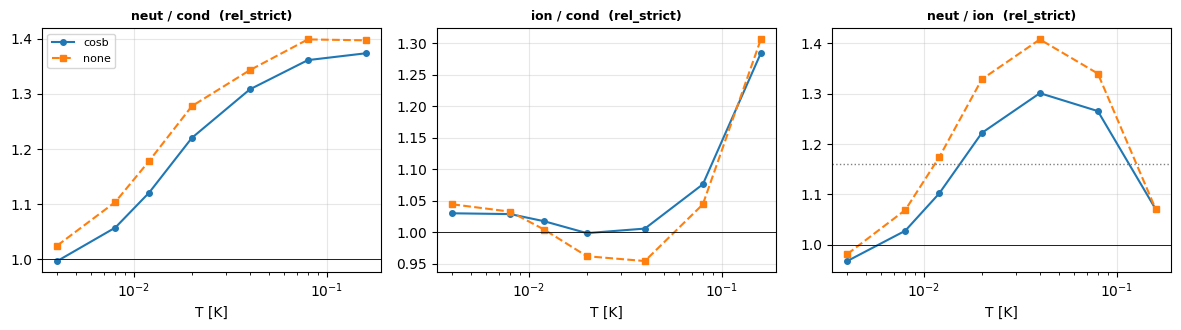

In [20]:
def fam_ratio_of(P, wt, obs):
    m = [np.mean([P[n][wt][obs] for n in names_M[3 * g:3 * g + 3]]) for g in range(3)]
    return m[0] / m[2], m[1] / m[2], m[0] / m[1]

TS = (0.004, 0.008, 0.012, 0.02, 0.04, 0.08, 0.16)         # K
TAB = {}
print(f"{'T [K]':>6s} {'sigma':>6s} {'voxels':>7s} | {'cosb: neut/cond':>15s} {'ion/cond':>9s} {'neut/ion':>9s} |"
      f" {'none: neut/cond':>15s} {'ion/cond':>9s} {'neut/ion':>9s}")

for T in TS:
    P = {n: paper_like(RES[n]["vec"], RES[n]["scale"], floor_threshold=T) for n in names_M}
    TAB[T] = {wt: fam_ratio_of(P, wt, "rel_strict") for wt in ("cosb", "none")}
    nsel = int(np.mean([P[n]["cosb"]["n_sel"] for n in names_M]))
    c, nn = TAB[T]["cosb"], TAB[T]["none"]

    print(f"{T:6.3f} {T / np.asarray(SIGMA).mean():6.1f} {nsel:7d} | {c[0]:15.3f} {c[1]:9.3f} {c[2]:9.3f} |"
          f" {nn[0]:15.3f} {nn[1]:9.3f} {nn[2]:9.3f}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for i, ttl in enumerate(("neut / cond", "ion / cond", "neut / ion")):
    for wt, st in (("cosb", "o-"), ("none", "s--")):

        axs[i].plot(TS, [TAB[T][wt][i] for T in TS], st, ms=4, label=wt)
    axs[i].axhline(1.0, color="k", lw=0.6)
    axs[i].set_xscale("log")
    axs[i].grid(alpha=0.3)
    axs[i].set_title(f"{ttl}  (rel_strict)", fontsize=9, weight="bold")
    axs[i].set_xlabel("T [K]")

axs[2].axhline(1.16, color="gray", ls=":", lw=1)            # paper Fig. 3: neutral vs ionised, relative residual, > 1.16
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

v_dev 35: done in 24 s
v_dev 40: done in 24 s
v_dev 50: done in 24 s
v_dev 60: done in 23 s
v_dev 80: done in 23 s
 v_dev  R_abs (neutral)  R_abs / LAB flux
    35           3241.9              1.17
    40           2557.9              1.19
    50           1716.8              1.22
    60           1204.3              1.27
    80            796.5              1.45


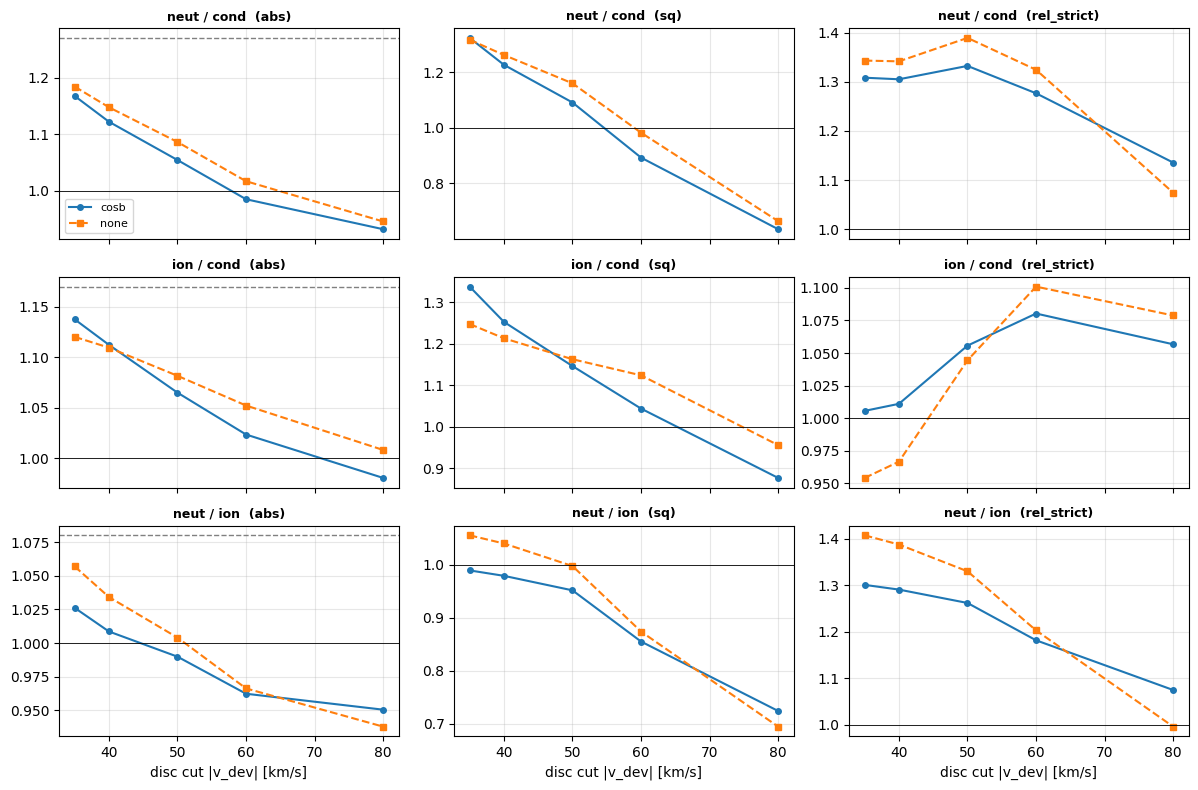

In [21]:
VDS = globals().get("VDS", {})

def run_vdev_scan(vdevs):
    global V_DEV
    keep_v = V_DEV
    
    try:
        for vd in vdevs:
            key = (vd, B_CUT, L_CUT, REL_FLOOR)

            if key in VDS:
                continue

            t0 = time.time()
            V_DEV = vd
            cv = make_cmp_variant()
            out = {}

            for nm in names_M:
                cube, ax_ = load_model(nm, GRID)
                r = cv.evaluate(cv.model_cmp(cube, ax_), keep_vectors=True)

                out[nm] = dict(R_abs=r["R_abs"], 
                               flux=r["flux_lab"], 
                               PL=paper_like(r["vec"], r["scale"], floor_threshold=0.04))
                
            VDS[key] = out
            print(f"v_dev {vd:g}: done in {time.time() - t0:.0f} s")

    finally:
        V_DEV = keep_v

VD_LIST = [35.0, 40.0, 50.0, 60.0, 80.0]
run_vdev_scan(VD_LIST)
get = lambda vd: VDS[(vd, B_CUT, L_CUT, REL_FLOOR)]

print(f"{'v_dev':>6s} {'R_abs (neutral)':>16s} {'R_abs / LAB flux':>17s}")

for vd in VD_LIST:
    o = get(vd)
    print(f"{vd:6g} {np.mean([o[n]['R_abs'] for n in names_M[:3]]):16.1f} "
          f"{np.mean([o[n]['R_abs'] / o[n]['flux'] for n in names_M[:3]]):17.2f}")

fig, axs = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for j, obs in enumerate(("abs", "sq", "rel_strict")):
    for wt, st in (("cosb", "o-"), ("none", "s--")):

        rr = np.array([fam_ratio_of({n: get(vd)[n]["PL"] for n in names_M}, wt, obs) for vd in VD_LIST])
        for i in range(3):
            axs[i, j].plot(VD_LIST, rr[:, i], st, ms=4, label=wt)

    for i, ttl in enumerate(("neut / cond", "ion / cond", "neut / ion")):
        axs[i, j].axhline(1.0, color="k", lw=0.6)
        axs[i, j].grid(alpha=0.3)
        axs[i, j].set_title(f"{ttl}  ({obs})", fontsize=9, weight="bold")

        if obs == "abs":
            axs[i, j].axhline([1.27, 1.17, 1.08][i], color="gray", ls="--", lw=1)

    axs[-1, j].set_xlabel("disc cut |v_dev| [km/s]")

axs[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. The residual as written in Marasco's own C++ code
The Li+23 repository holds the code in two versions. What they do, as we read from the source:

* **Milky Way (Marasco) version:** (`c++/extragas_copia.cpp`, compare_to = cube, `threshold_res` = **0.04 K** in the parameter file). 
    * The disk cut blanks the model wherever the data are blank, **before** the smoothing. 
    * The smoothing renormalizes over the non-blank neighbours (as `normalized convolution` here).
    * The flux of the model is scaled to the data over all non-blank voxels, $\cos(b)$ weighted. 
    * Then, over the voxels with **data > T or model > T** (signed, strict), the same selection for all three: 
        * `R1 = sum cos b |D - M|`, 
        * `R2 = sum cos b (D - M)^2`, 
        * `R3 = sum cos b |D - M| / max(D, M)` (the paper prints D + M).

* **NGC 2403 (Li) version:** (`c++/extragas_fit_n2403.cpp`, the one `grid_run.py` runs): 
    * Voxels with data > 2 rms or model > 2 rms (rms hard-coded, 0.00019), 
    * The residual is `|D - M|`; and, 
    * If `use_blanks` is set (the parameter file that sets it is not in the repository, but I assume it is used), **cos b x model added for every voxel that is not counted**, which punishes model flux where nothing is above the threshold.

So, the threshold with a penalty for non-matching pixels is: a voxel where only one cube is above T counts in full ($|D - M|$ is then large), a voxel where both are below counts nothing, plus optionally the model's sub-threshold flux ('blank'). 

`code_like()` does exactly this on our comparison grid. Below, the family ratios for every residual at T = 0.04 K (Marasco) and at $k$ sigma ($k = 2$, Li); then the whole threshold range for the three residuals (the 9a table above did this for the relative one only).

threshold  voxels residual    neut/cond  ion/cond  neut/ion
0.04 K      28327 abs             1.215     1.169     1.040
0.04 K      28327 sq              1.327     1.341     0.990
0.04 K      28327 rel_max         1.269     0.983     1.291
0.04 K      28327 rel_sum         1.308     1.006     1.301
0.04 K      28327 abs_blank       1.235     1.143     1.081

2 sigma     77497 abs             1.181     1.144     1.032
2 sigma     77497 sq              1.325     1.338     0.990
2 sigma     77497 rel_max         1.044     1.009     1.035
2 sigma     77497 rel_sum         1.024     1.022     1.003
2 sigma     77497 abs_blank       1.186     1.143     1.037

3 sigma     63861 abs             1.187     1.146     1.036
3 sigma     63861 sq              1.325     1.339     0.990
3 sigma     63861 rel_max         1.078     0.995     1.083
3 sigma     63861 rel_sum         1.065     1.009     1.056
3 sigma     63861 abs_blank       1.194     1.143     1.044

5 sigma     48664 abs             1.1

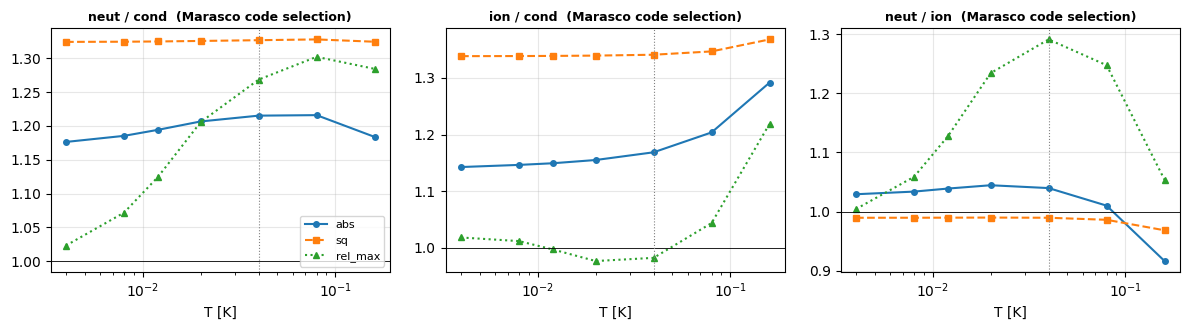

In [22]:
THR = [("0.04 K", dict(floor_threshold=0.04)), 
       ("2 sigma", dict(k_level=2.0, sigma=SIGMA)), 
       ("3 sigma", dict(k_level=3.0, sigma=SIGMA)), 
       ("5 sigma", dict(k_level=5.0, sigma=SIGMA)), 
       ("10 sigma", dict(k_level=10.0, sigma=SIGMA))]

OBS10 = ("abs", "sq", "rel_max", "rel_sum", "abs_blank")
CLS = {lab_: {n: code_like(RES[n]["vec"], **kw) for n in names_M} for lab_, kw in THR}

def fam_means_cl(P, obs):
    return [np.mean([P[n][obs] for n in names_M[3 * g:3 * g + 3]]) for g in range(3)]

print(f"{'threshold':9s} {'voxels':>7s} {'residual':10s} {'neut/cond':>10s} {'ion/cond':>9s} {'neut/ion':>9s}")
for lab_, P in CLS.items():
    nsel = int(np.mean([P[n]["n_sel"] for n in names_M]))
    for obs in OBS10:
        m = fam_means_cl(P, obs)
        print(f"{lab_:9s} {nsel:7d} {obs:10s} {m[0] / m[2]:10.3f} {m[1] / m[2]:9.3f} {m[0] / m[1]:9.3f}")
    print()
print("paper (hv = 70, Table 1): abs 1.27 / 1.17 / 1.08;  Fig. 3, neutral vs ionised: abs ~1.07, sq ~1.035, relative > 1.16")
print("rel_sum = |D-M|/(D+M) as printed in the paper, rel_max = |D-M|/max(D,M) as coded; "
      "abs_blank = abs + the use_blanks term of the NGC 2403 version")

TS10 = (0.004, 0.008, 0.012, 0.02, 0.04, 0.08, 0.16)         # K
TAB10 = {o: [] for o in ("abs", "sq", "rel_max")}

for T in TS10:
    P = {n: code_like(RES[n]["vec"], floor_threshold=T) for n in names_M}
    for o in TAB10:
        m = fam_means_cl(P, o); TAB10[o].append((m[0] / m[2], m[1] / m[2], m[0] / m[1]))

print(f"\n{'T [K]':>6s} {'sigma':>6s} | " + " | ".join(f"{o + ': neut/cond ion/cond neut/ion':^34s}" for o in TAB10))

for i, T in enumerate(TS10):
    print(f"{T:6.3f} {T / SIGMA_NUM:6.1f} | " + 
          " | ".join(f"{TAB10[o][i][0]:>12.3f} {TAB10[o][i][1]:>8.3f} {TAB10[o][i][2]:>8.3f}  " for o in TAB10))
    
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for j, ttl in enumerate(("neut / cond", "ion / cond", "neut / ion")):
    for o, st in (("abs", "o-"), ("sq", "s--"), ("rel_max", "^:")):
        axs[j].plot(TS10, [r[j] for r in TAB10[o]], st, ms=4, label=o)

    axs[j].axhline(1.0, color="k", lw=0.6); axs[j].set_xscale("log")
    axs[j].grid(alpha=0.3)
    axs[j].axvline(0.04, color="gray", lw=0.8, ls=":")
    axs[j].set_title(ttl + "  (Marasco code selection)", fontsize=9, weight="bold")
    axs[j].set_xlabel("T [K]")

axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## What have we learned?

* **On the noise:** The noise recipe seems to work well, although there are some caveats with the non-Gaussian tails and a possible baseline problem. The model and LAB have different brightness distributions, narrower at faint levels (with steep edges) and broader at bright ones when looking from an absolute $\sigma$ perspective.

* **The nature of the differences:** They come from how the models distribute gas in velocity and brightness. Condensation concentrates gas near the disk, ionized keeps it at negative velocity, and neutral spreads it widest. Because our model currently seems to be smaller than LAB with less diffuse gas, without making sure our residual is correctly calibrated, it will always try to go for `f_ion=1`.

* **The paper’s abs ranking:** Marasco+12 seem to have mainly used a near-disk ranking that penalizes neutral with faint emission. Condensation was robustly best, but the effect is smaller than the paper’s. I initially did not know what they exactly used, so I tried to get rid of more near-disk gas makes the agreement of ranking worse (no |l| or |b| cut matched). After investigating [their repository](https://github.com/Anqi-Li-rug/extragas_grid), only with the residual as implemented in Marasco’s own code do the absolute residual reproduce their Table 1 ordering and similar ratios: neutral/condensation = 1.22 and ionized/condensation = 1.17, against 1.27 and 1.17 in the paper. Small differences still remain because the codes and equations of motion differ. However, this is satisfactory for our purposes.

* **For the project:** Our target, IVC/HVC gas, sits in the far regime. The grid-search optimum will therefore depend on which zone dominates the residual. That is choice we have to make. After making comparisons with Marasco, we do not need to follow their approach. Fitting zone by zone, or weighting the zones explicitly, could be design choices. I don't know more about this than that.

* **Limits:** These are single-hv0 results for three families. The plot values are read by eye, and the errors are seed-only. Still, should be broadly applicable. I am yet to investigate how `R_clump=200` should affect the results here.